In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn scipy joblib

In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.feature_selection import VarianceThreshold

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [9]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [11]:
print("Missing values in each column:")

print(df.isnull().sum())

print("\nTotal missing values:")

print(df.isnull().sum().sum())

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total missing values:
207


In [13]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Columns containing missing values:")

print(missing_values)

Columns containing missing values:
total_bedrooms    207
dtype: int64


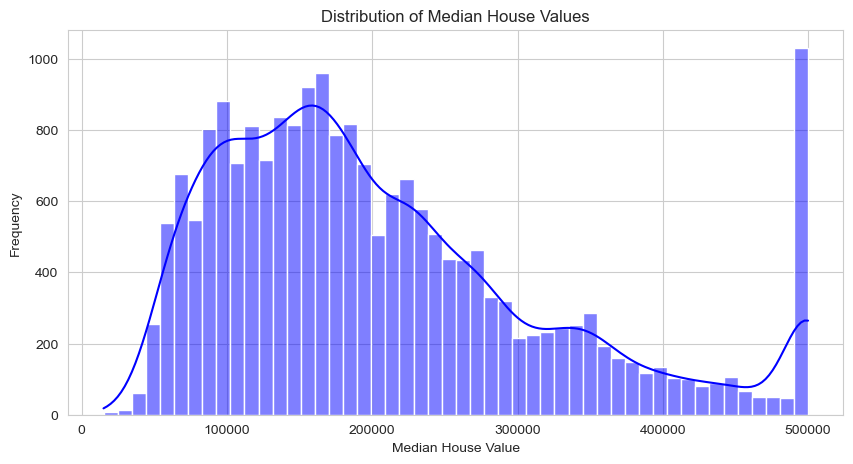

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['median_house_value'],
    bins=50,
    kde=True,
    color='blue'
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

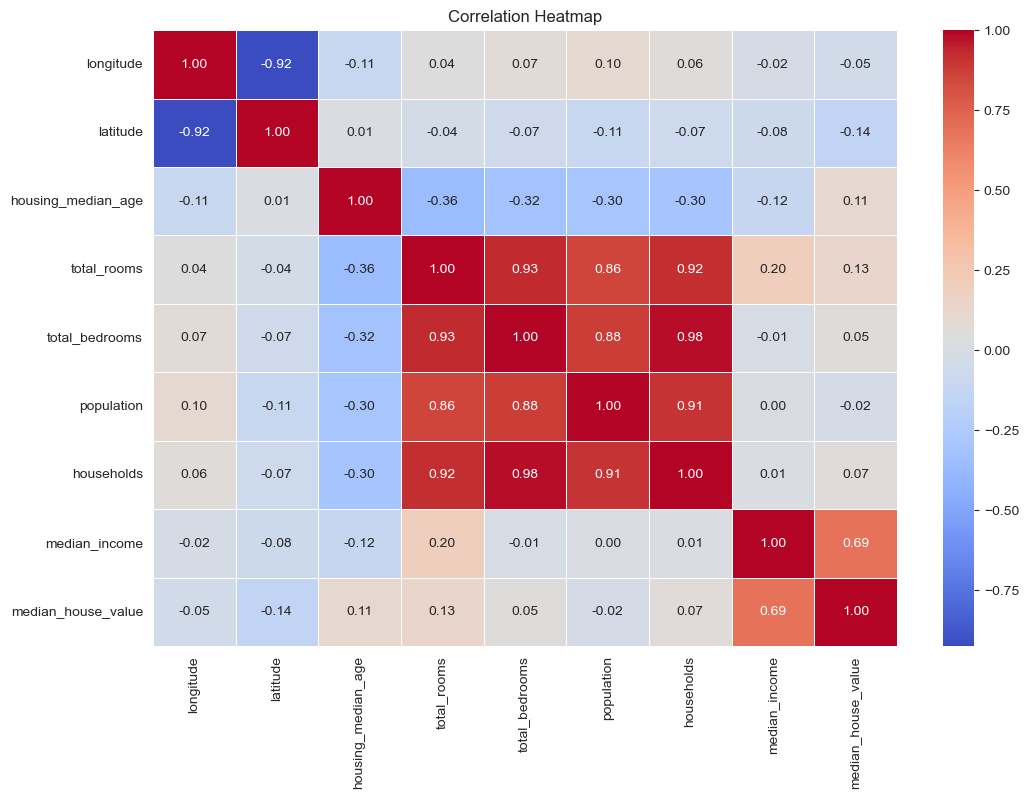

In [17]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

correlation_matrix = numeric_df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


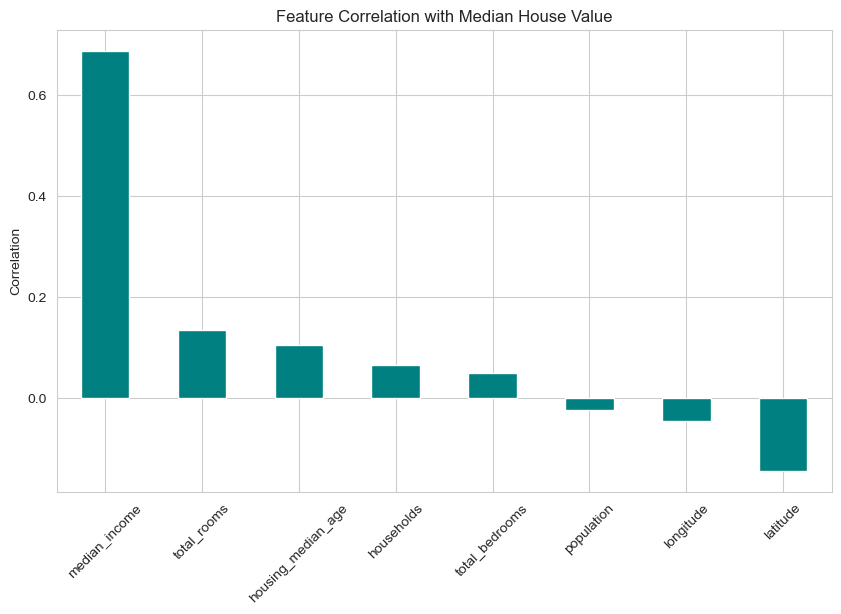

In [19]:
target_corr = correlation_matrix['median_house_value'].sort_values(
    ascending=False
)

print(target_corr)

plt.figure(figsize=(10, 6))

target_corr.drop('median_house_value').plot(
    kind='bar',
    color='teal'
)

plt.title("Feature Correlation with Median House Value")
plt.ylabel("Correlation")

plt.xticks(rotation=45)

plt.show()

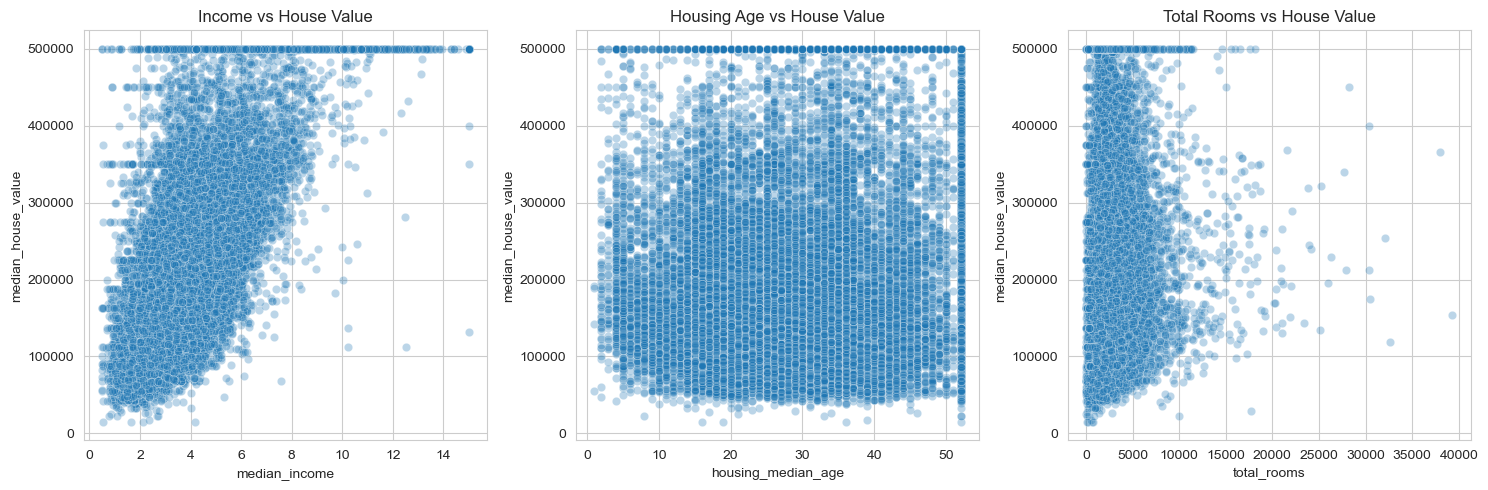

In [21]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

sns.scatterplot(
    data=df,
    x='median_income',
    y='median_house_value',
    alpha=0.3
)

plt.title("Income vs House Value")


plt.subplot(1, 3, 2)

sns.scatterplot(
    data=df,
    x='housing_median_age',
    y='median_house_value',
    alpha=0.3
)

plt.title("Housing Age vs House Value")


plt.subplot(1, 3, 3)

sns.scatterplot(
    data=df,
    x='total_rooms',
    y='median_house_value',
    alpha=0.3
)

plt.title("Total Rooms vs House Value")

plt.tight_layout()

plt.show()

In [23]:
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

df['population_per_household'] = (
    df['population'] / df['households']
)

df['income_per_room'] = (
    df['median_income'] / df['total_rooms']
)

df['income_per_household'] = (
    df['median_income'] / df['households']
)

print("Interaction features created successfully!")

df.head()

Interaction features created successfully!


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_per_room,income_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,0.009460,0.066073
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,0.001169,0.007295
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,0.004947,0.041002
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,0.004429,0.025768
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,0.002364,0.014850


In [25]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced with NaN.")

print(df.isnull().sum())

Infinite values replaced with NaN.
longitude                     0
latitude                      0
housing_median_age            0
total_rooms                   0
total_bedrooms              207
population                    0
households                    0
median_income                 0
median_house_value            0
ocean_proximity               0
rooms_per_household           0
bedrooms_per_room           207
population_per_household      0
income_per_room               0
income_per_household          0
dtype: int64


In [27]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']

print("Feature shape:", X.shape)

print("Target shape:", y.shape)

Feature shape: (20640, 14)
Target shape: (20640,)


In [29]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")

print(numeric_features)

print("\nCategorical Features:")

print(categorical_features)

Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_room', 'income_per_household']

Categorical Features:
['ocean_proximity']


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (16512, 14)
Testing data: (4128, 14)


In [33]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [35]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)

print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (16512, 18)
Testing processed shape: (4128, 18)


In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use numerical training features only
vif_imputer = SimpleImputer(strategy='median')

X_vif = vif_imputer.fit_transform(
    X_train[numeric_features]
)

vif_scaler = StandardScaler()

X_vif = vif_scaler.fit_transform(X_vif)

vif_df = pd.DataFrame(
    X_vif,
    columns=numeric_features
)

vif_results = pd.DataFrame()

vif_results['Feature'] = vif_df.columns

vif_results['VIF'] = [
    variance_inflation_factor(
        vif_df.values, i
    )
    for i in range(vif_df.shape[1])
]

vif_results = vif_results.sort_values(
    by='VIF',
    ascending=False
)

print(vif_results)

                     Feature        VIF
4             total_bedrooms  50.023875
6                 households  45.998312
3                total_rooms  19.102693
1                   latitude   9.379230
0                  longitude   9.055223
5                 population   6.830480
11           income_per_room   4.768506
12      income_per_household   4.577546
9          bedrooms_per_room   2.890368
7              median_income   2.182628
8        rooms_per_household   1.789061
2         housing_median_age   1.259943
10  population_per_household   1.142514


In [39]:
ols_model = LinearRegression()

ols_model.fit(
    X_train_processed,
    y_train
)

ols_predictions = ols_model.predict(
    X_test_processed
)

print("OLS model trained successfully!")

OLS model trained successfully!


In [41]:
ols_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ols_predictions
    )
)

ols_mae = mean_absolute_error(
    y_test,
    ols_predictions
)

ols_r2 = r2_score(
    y_test,
    ols_predictions
)

print("OLS Regression Results")

print("-------------------------")

print("RMSE:", ols_rmse)

print("MAE:", ols_mae)

print("R2 Score:", ols_r2)

OLS Regression Results
-------------------------
RMSE: 69042.95429099532
MAE: 49612.3821641705
R2 Score: 0.6362258183221836


In [43]:
ridge_model = Ridge()

ridge_params = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(
    X_train_processed,
    y_train
)

print("Best Ridge Parameters:")

print(ridge_grid.best_params_)

print("\nBest Cross Validation RMSE:")

print(-ridge_grid.best_score_)

Best Ridge Parameters:
{'alpha': 100}

Best Cross Validation RMSE:
68704.95698238321


In [45]:
best_ridge = ridge_grid.best_estimator_

ridge_predictions = best_ridge.predict(
    X_test_processed
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ridge_predictions
    )
)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_predictions
)

ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)

print("Ridge Regression Results")

print("-------------------------")

print("RMSE:", ridge_rmse)

print("MAE:", ridge_mae)

print("R2 Score:", ridge_r2)

Ridge Regression Results
-------------------------
RMSE: 69158.46392702532
MAE: 49625.21523923909
R2 Score: 0.6350076035676857


In [60]:
lasso_model = Lasso(max_iter=20000)

lasso_params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid=lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(
    X_train_processed,
    y_train
)
[='
print("Best Lasso Parameters:")

print(lasso_grid.best_params_)

print("\nBest Cross Validation RMSE:")'''''''''''''''''''''''''''''''''''"""""

print(-lasso_grid.best_score_)

SyntaxError: unterminated string literal (detected at line 19) (2459942750.py, line 19)

In [62]:
best_lasso = lasso_grid.best_estimator_

lasso_predictions = best_lasso.predict(
    X_test_processed
)

lasso_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lasso_predictions
    )
)

lasso_mae = mean_absolute_error(
    y_test,
    lasso_predictions
)

lasso_r2 = r2_score(
    y_test,
    lasso_predictions
)

print("Lasso Regression Results")

print("-------------------------")

print("RMSE:", lasso_rmse)

print("MAE:", lasso_mae)

print("R2 Score:", lasso_r2)

Lasso Regression Results
-------------------------
RMSE: 69098.5706386365
MAE: 49616.64986938053
R2 Score: 0.6356395183805819


In [64]:

results = pd.DataFrame({
    'Model': [
        'OLS',
        'Ridge',
        'Lasso'
    ],

    'RMSE': [
        ols_rmse,
        ridge_rmse,
        lasso_rmse
    ],

    'MAE': [
        ols_mae,
        ridge_mae,
        lasso_mae
    ],

    'R2 Score': [
        ols_r2,
        ridge_r2,
        lasso_r2
    ]
})

results = results.sort_values(
    by='RMSE'
)

print(results)














































































                

   Model          RMSE           MAE  R2 Score
0    OLS  69042.954291  49612.382164  0.636226
2  Lasso  69098.570639  49616.649869  0.635640
1  Ridge  69158.463927  49625.215239  0.635008


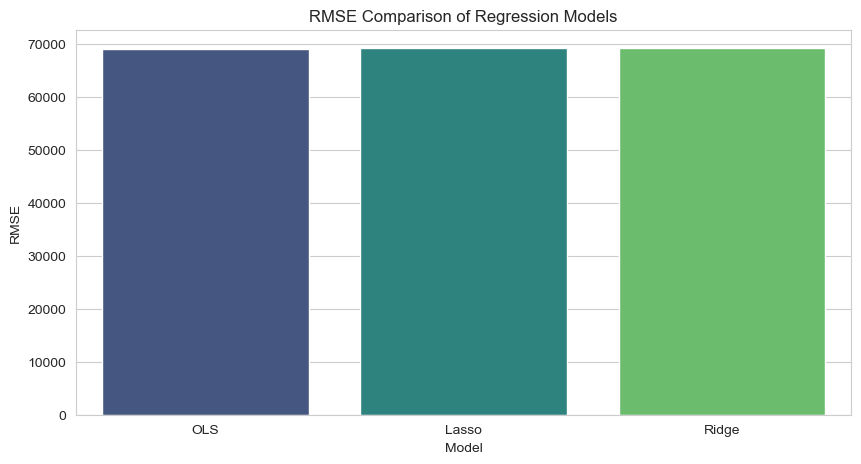

In [66]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("RMSE Comparison of Regression Models")

plt.ylabel("RMSE")

plt.show()

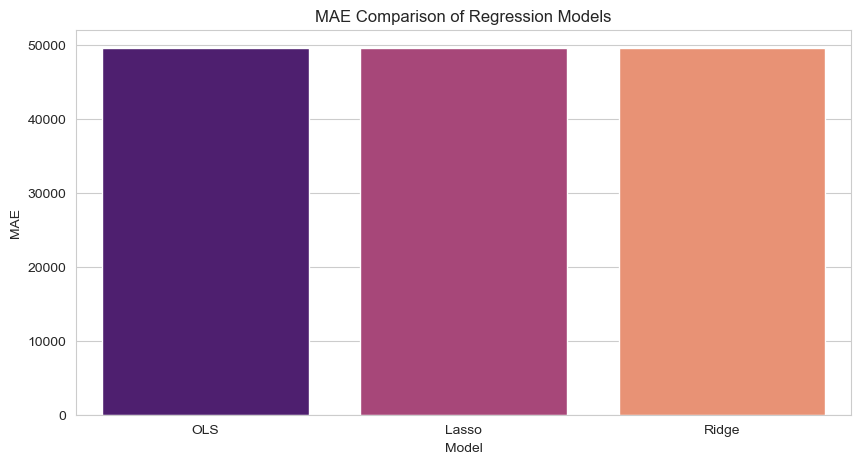

In [68]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Model',
    y='MAE',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title("MAE Comparison of Regression Models")

plt.ylabel("MAE")

plt.show()

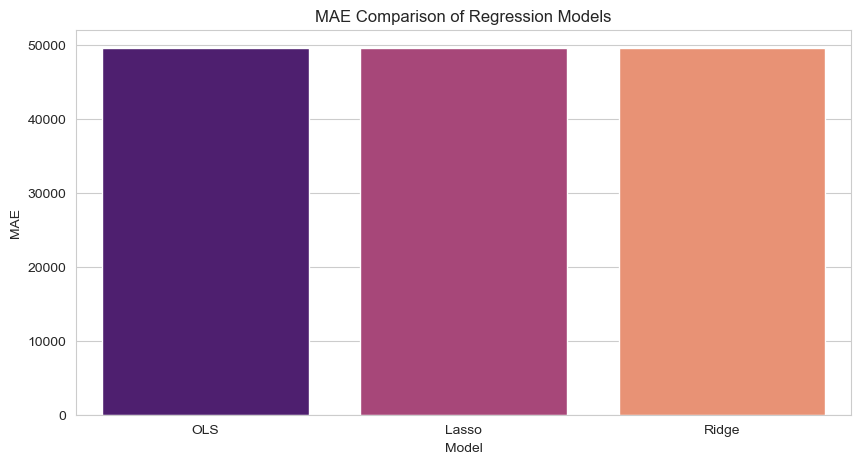

In [70]:
                                plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Model',
    y='MAE',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title("MAE Comparison of Regression Models")

plt.ylabel("MAE")

plt.show()

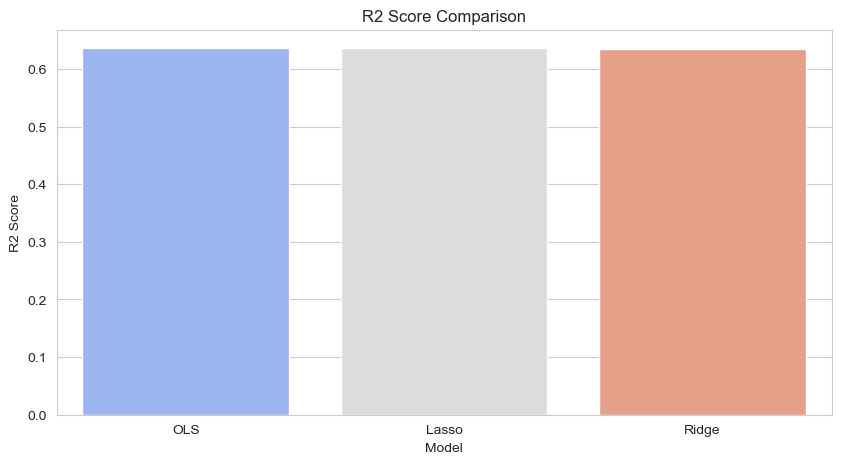

In [72]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Model',
    y='R2 Score',
    hue='Model',
    palette='coolwarm',
    legend=False
)

plt.title("R2 Score Comparison")

plt.ylabel("R2 Score")

plt.show()

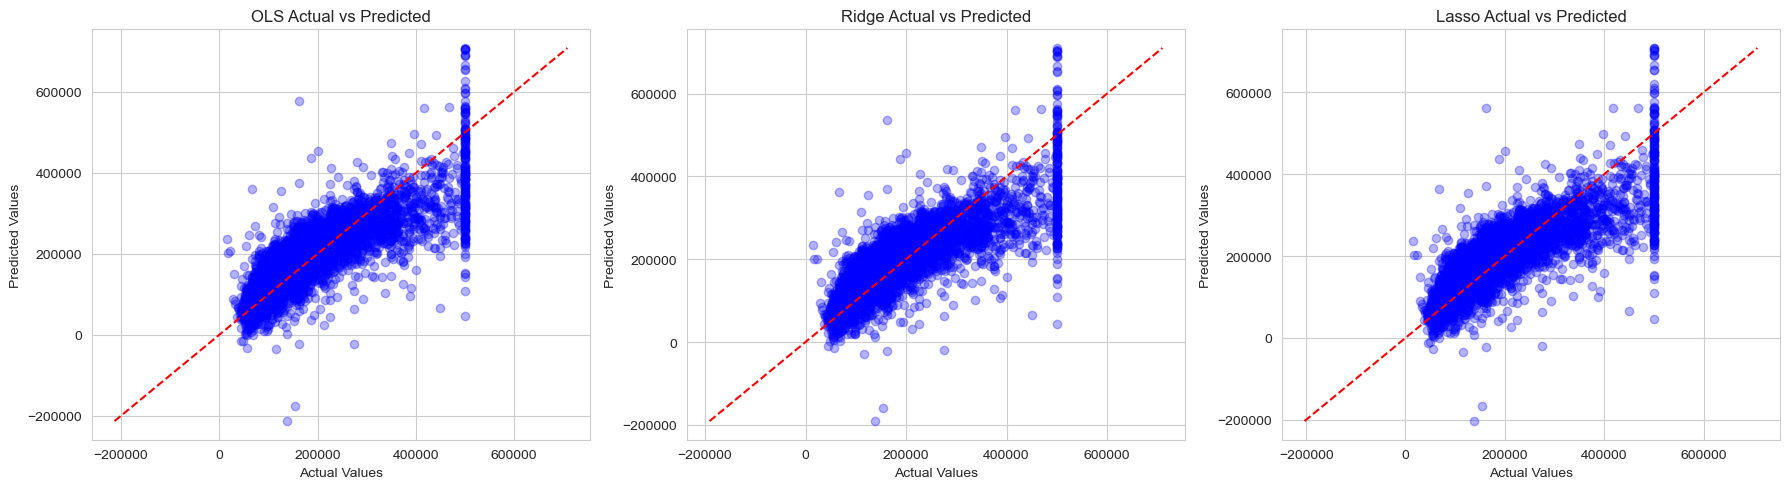

In [74]:
predictions = {
    'OLS': ols_predictions,
    'Ridge': ridge_predictions,
    'Lasso': lasso_predictions
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (name, pred) in zip(
    axes,
    predictions.items()
):

    ax.scatter(
        y_test,
        pred,
        alpha=0.3,
        color='blue'
    )

    min_val = min(y_test.min(), pred.min())
    max_val = max(y_test.max(), pred.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        'r--'
    )

    ax.set_title(name + " Actual vs Predicted")

    ax.set_xlabel("Actual Values")

    ax.set_ylabel("Predicted Values")

plt.tight_layout()

plt.show()

In [76]:
ols_residuals = y_test - ols_predictions

ridge_residuals = y_test - ridge_predictions

lasso_residuals = y_test - lasso_predictions

print("Residuals calculated successfully!")

Residuals calculated successfully!


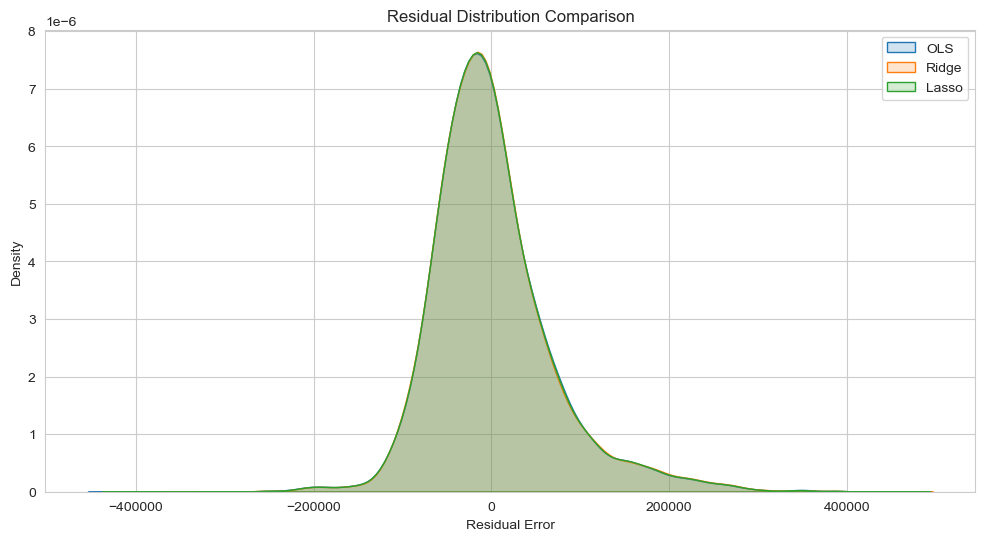

In [78]:
plt.figure(figsize=(12, 6))

sns.kdeplot(
    ols_residuals,
    label='OLS',
    fill=True,
    alpha=0.2
)

sns.kdeplot(
    ridge_residuals,
    label='Ridge',
    fill=True,
    alpha=0.2
)

sns.kdeplot(
    lasso_residuals,
    label='Lasso',
    fill=True,
    alpha=0.2
)

plt.title("Residual Distribution Comparison")

plt.xlabel("Residual Error")

plt.ylabel("Density")

plt.legend()

plt.show()

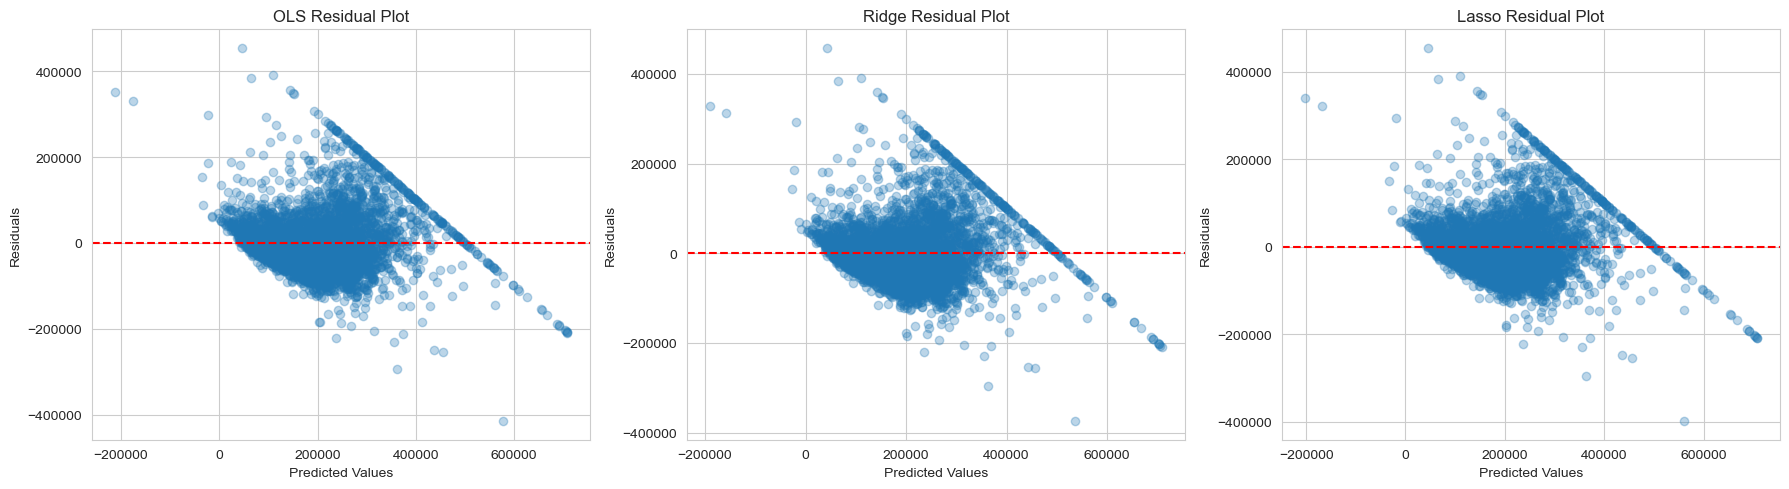

In [80]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

residual_data = [
    ('OLS', ols_predictions, ols_residuals),
    ('Ridge', ridge_predictions, ridge_residuals),
    ('Lasso', lasso_predictions, lasso_residuals)
]

for ax, (name, pred, residuals) in zip(
    axes,
    residual_data
):

    ax.scatter(
        pred,
        residuals,
        alpha=0.3
    )

    ax.axhline(
        y=0,
        color='red',
        linestyle='--'
    )

    ax.set_title(name + " Residual Plot")

    ax.set_xlabel("Predicted Values")

    ax.set_ylabel("Residuals")

plt.tight_layout()

plt.show()

In [82]:
best_model_name = results.iloc[0]['Model']

print("Best Performing Model:", best_model_name)

print("\nBest Model Performance:")

print(results.iloc[0])

Best Performing Model: OLS

Best Model Performance:
Model                OLS
RMSE        69042.954291
MAE         49612.382164
R2 Score        0.636226
Name: 0, dtype: object


In [84]:
feature_names = preprocessor.get_feature_names_out()

lasso_coefficients = best_lasso.coef_

lasso_feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lasso_coefficients
})

lasso_feature_df['Absolute Coefficient'] = (
    lasso_feature_df['Coefficient'].abs()
)

lasso_feature_df = lasso_feature_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

print("Top 15 Lasso Features:")

print(lasso_feature_df.head(15))

print("\nNumber of selected features:")

print(
    np.sum(lasso_coefficients != 0),
    "out of",
    len(lasso_coefficients)
)

Top 15 Lasso Features:
                            Feature   Coefficient  Absolute Coefficient
7                num__median_income  79852.814708          79852.814708
1                     num__latitude -54155.772163          54155.772163
0                    num__longitude -53669.031069          53669.031069
5                   num__population -44899.654511          44899.654511
6                   num__households  38089.594225          38089.594225
14      cat__ocean_proximity_INLAND -35199.042121          35199.042121
9            num__bedrooms_per_room  17044.641955          17044.641955
2           num__housing_median_age  14015.314101          14015.314101
8          num__rooms_per_household   7373.872106           7373.872106
4               num__total_bedrooms   6644.888426           6644.888426
3                  num__total_rooms   4828.525128           4828.525128
16    cat__ocean_proximity_NEAR BAY  -3096.900011           3096.900011
17  cat__ocean_proximity_NEAR OCEAN   307

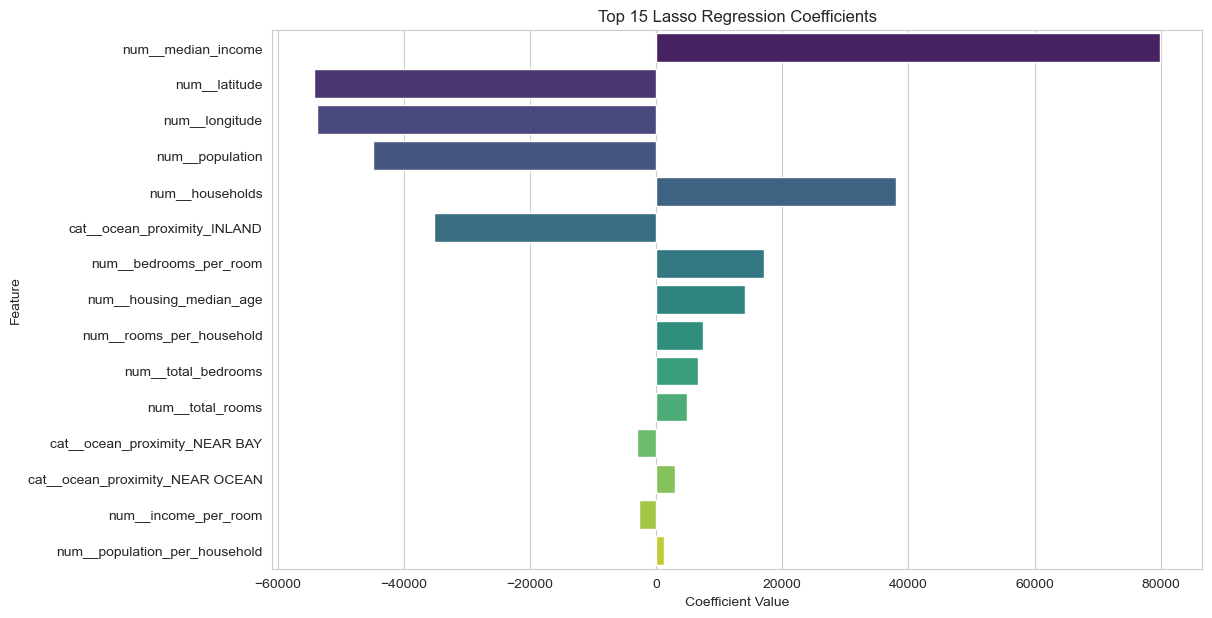

In [86]:
top_features = lasso_feature_df.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x='Coefficient',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title("Top 15 Lasso Regression Coefficients")

plt.xlabel("Coefficient Value")

plt.ylabel("Feature")

plt.show()

In [88]:
new_house = pd.DataFrame({
    'longitude': [-122.23],
    'latitude': [37.88],
    'housing_median_age': [41],
    'total_rooms': [880],
    'total_bedrooms': [129],
    'population': [322],
    'households': [126],
    'median_income': [8.3252],
    'ocean_proximity': ['NEAR BAY']
})

# Create engineered features
new_house['rooms_per_household'] = (
    new_house['total_rooms'] / new_house['households']
)

new_house['bedrooms_per_room'] = (
    new_house['total_bedrooms'] / new_house['total_rooms']
)

new_house['population_per_household'] = (
    new_house['population'] / new_house['households']
)

new_house['income_per_room'] = (
    new_house['median_income'] / new_house['total_rooms']
)

new_house['income_per_household'] = (
    new_house['median_income'] / new_house['households']
)

new_house_processed = preprocessor.transform(
    new_house
)

predicted_price = best_ridge.predict(
    new_house_processed
)

print(
    "Predicted Median House Value: $",
    round(predicted_price[0], 2)
)

Predicted Median House Value: $ 408277.95


In [90]:
import joblib

joblib.dump(
    preprocessor,
    'housing_preprocessor.pkl'
)

joblib.dump(
    best_ridge,
    'california_housing_ridge_model.pkl'
)

print("Models saved successfully!")

Models saved successfully!


In [92]:
print("=" * 60)

print("CALIFORNIA HOUSING PRICE PREDICTION")

print("=" * 60)

print("\nMODEL PERFORMANCE")

print(results.to_string(index=False))

print("\nBEST MODEL:", best_model_name)

print("\nBEST RIDGE ALPHA:", ridge_grid.best_params_['alpha'])

print("\nBEST LASSO ALPHA:", lasso_grid.best_params_['alpha'])

print("\nPROJECT COMPLETED SUCCESSFULLY!")

print("=" * 60)

CALIFORNIA HOUSING PRICE PREDICTION

MODEL PERFORMANCE
Model         RMSE          MAE  R2 Score
  OLS 69042.954291 49612.382164  0.636226
Lasso 69098.570639 49616.649869  0.635640
Ridge 69158.463927 49625.215239  0.635008

BEST MODEL: OLS

BEST RIDGE ALPHA: 100

BEST LASSO ALPHA: 100

PROJECT COMPLETED SUCCESSFULLY!
